has_ai
0    9.761356
1    9.099042
Name: hours, dtype: float64
Estimated AI effect: -0.66
95% confidence range: [-1.04, -0.28]


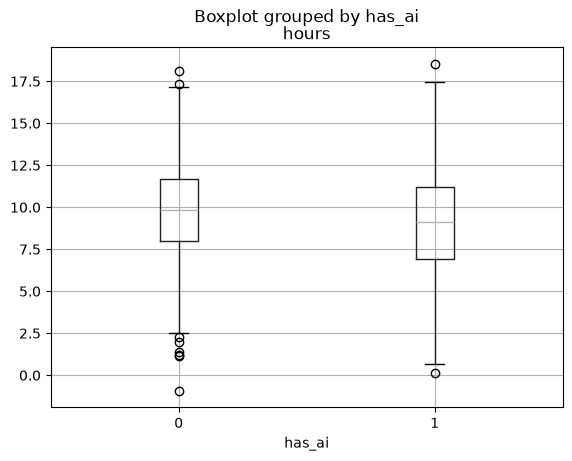

In [2]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# 1,000 fake tickets; roughly half handled by teams with AI
df = pd.DataFrame({"has_ai": rng.integers(0, 2, size=1000)})

# Resolution time: about 10 hours on average, and AI saves 1 hour
df["hours"] = rng.normal(10, 3, size=1000) - 1 * df["has_ai"]

print(df.groupby("has_ai")["hours"].mean())

model = smf.ols("hours ~ has_ai", data=df).fit()
print("Estimated AI effect:", round(model.params["has_ai"], 2))
print("95% confidence range:", model.conf_int().loc["has_ai"].round(2).tolist())

df.boxplot(column="hours", by="has_ai")
plt.show()